# Exploratory Data Analysis (EDA)
## Personal Cognitive Load & Focus Monitoring System

This notebook performs exploratory data analysis on the cognitive load monitoring dataset.

### Objectives:
1. Load and inspect the raw data
2. Understand data distributions
3. Identify patterns and relationships
4. Check for data quality issues
5. Visualize key metrics


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Set paths
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_RAW}")


Project root: /home/pnmynh/Documents/personal-cognitive-load-monitor
Data directory: /home/pnmynh/Documents/personal-cognitive-load-monitor/data/raw


In [2]:
# Load data
# Load the deterministic DVC input, generating the same seeded fixture if absent.
import sys
sys.path.append(str(PROJECT_ROOT / "src"))
from data_generator import generate_sample_data

sample_file = DATA_RAW / "sample_data.csv"
if not sample_file.exists():
    print("Generating sample data...")
    generate_sample_data(n_samples=200, output_path=sample_file)

df = pd.read_csv(sample_file)
print(f"Loaded {len(df)} records")
df.head()


Loaded 500 records


,date,focus_minutes,distraction_minutes,tasks_due,hours_to_deadline,cognitive_load_level,label_provenance
0,2025-01-01,148,255,0,124.71,LOW,synthetic_proxy
1,2025-01-01,147,155,2,123.86,LOW,synthetic_proxy
2,2025-01-02,312,101,8,15.06,HIGH,synthetic_proxy
3,2025-01-02,112,236,0,16.19,MEDIUM,synthetic_proxy
4,2025-01-03,218,81,9,4.94,HIGH,synthetic_proxy


In [3]:
# Basic information about the dataset
print("Dataset Info:")
print("=" * 50)
df.info()
print("\n" + "=" * 50)
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\n" + "=" * 50)
print("\nBasic Statistics:")
df.describe()


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  500 non-null    str    
 1   focus_minutes         500 non-null    int64  
 2   distraction_minutes   500 non-null    int64  
 3   tasks_due             500 non-null    int64  
 4   hours_to_deadline     500 non-null    float64
 5   cognitive_load_level  500 non-null    str    
 6   label_provenance      500 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 42.1 KB


Dataset Shape: (500, 7)

Missing Values:
date                    0
focus_minutes           0
distraction_minutes     0
tasks_due               0
hours_to_deadline       0
cognitive_load_level    0
label_provenance        0
dtype: int64


Basic Statistics:


,focus_minutes,distraction_minutes,tasks_due,hours_to_deadline
count,500.000000,500.000000,500.000000,500.000000
mean,217.278000,143.530000,5.068000,88.125540
std,75.536669,70.542253,3.087141,50.516677
min,82.000000,26.000000,0.000000,0.760000
25%,155.000000,85.000000,2.000000,43.775000
50%,210.000000,136.000000,5.000000,90.130000
75%,265.250000,197.000000,8.000000,132.647500
max,421.000000,322.000000,10.000000,167.820000


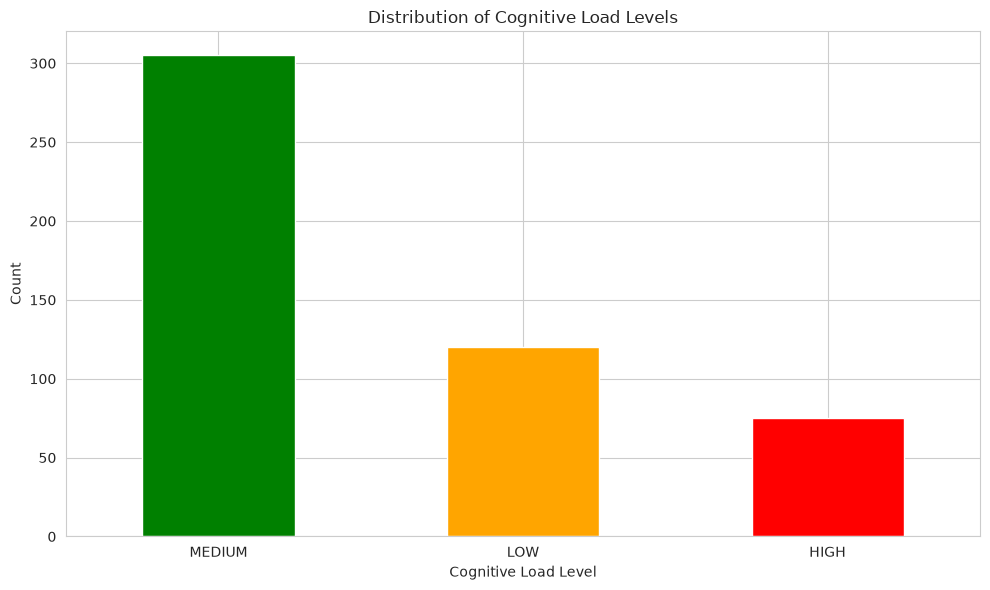


Cognitive Load Level Distribution:
cognitive_load_level
MEDIUM    305
LOW       120
HIGH       75
Name: count, dtype: int64

Percentage Distribution:
cognitive_load_level
MEDIUM    61.0
LOW       24.0
HIGH      15.0
Name: proportion, dtype: float64


In [4]:
# Distribution of cognitive load levels
if "cognitive_load_level" in df.columns:
    plt.figure(figsize=(10, 6))
    df["cognitive_load_level"].value_counts().plot(kind="bar", color=["green", "orange", "red"])
    plt.title("Distribution of Cognitive Load Levels")
    plt.xlabel("Cognitive Load Level")
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    print("\nCognitive Load Level Distribution:")
    print(df["cognitive_load_level"].value_counts())
    print("\nPercentage Distribution:")
    print(df["cognitive_load_level"].value_counts(normalize=True) * 100)


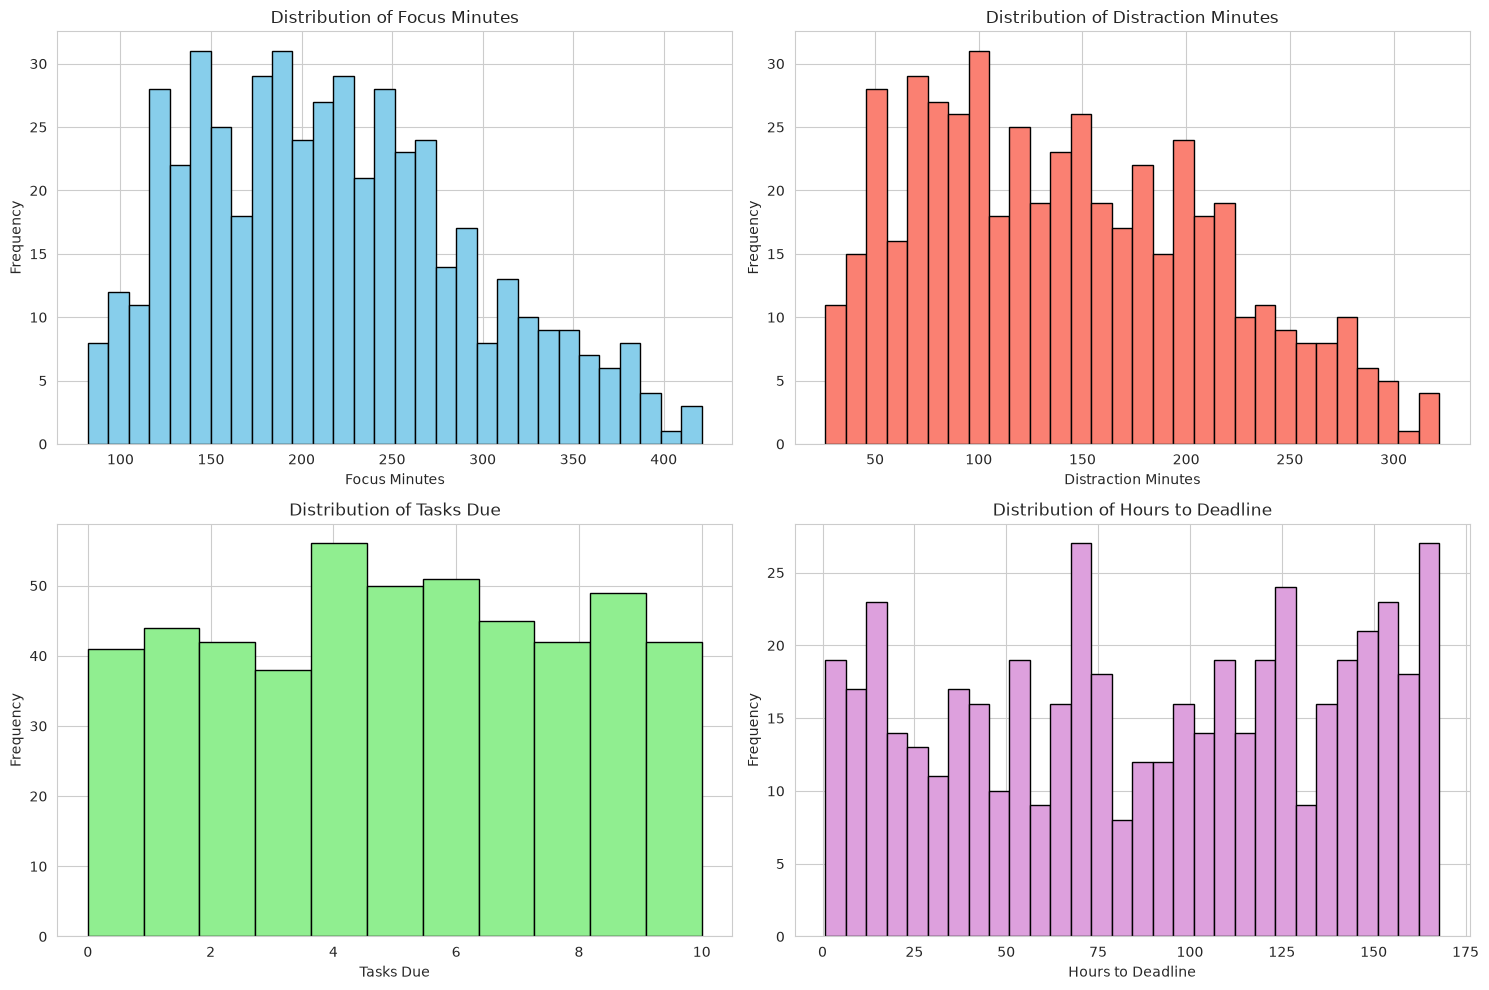

In [5]:
# Distribution of numerical features
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

df["focus_minutes"].hist(ax=axes[0, 0], bins=30, color="skyblue", edgecolor="black")
axes[0, 0].set_title("Distribution of Focus Minutes")
axes[0, 0].set_xlabel("Focus Minutes")
axes[0, 0].set_ylabel("Frequency")

df["distraction_minutes"].hist(ax=axes[0, 1], bins=30, color="salmon", edgecolor="black")
axes[0, 1].set_title("Distribution of Distraction Minutes")
axes[0, 1].set_xlabel("Distraction Minutes")
axes[0, 1].set_ylabel("Frequency")

df["tasks_due"].hist(ax=axes[1, 0], bins=11, color="lightgreen", edgecolor="black")
axes[1, 0].set_title("Distribution of Tasks Due")
axes[1, 0].set_xlabel("Tasks Due")
axes[1, 0].set_ylabel("Frequency")

df["hours_to_deadline"].hist(ax=axes[1, 1], bins=30, color="plum", edgecolor="black")
axes[1, 1].set_title("Distribution of Hours to Deadline")
axes[1, 1].set_xlabel("Hours to Deadline")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


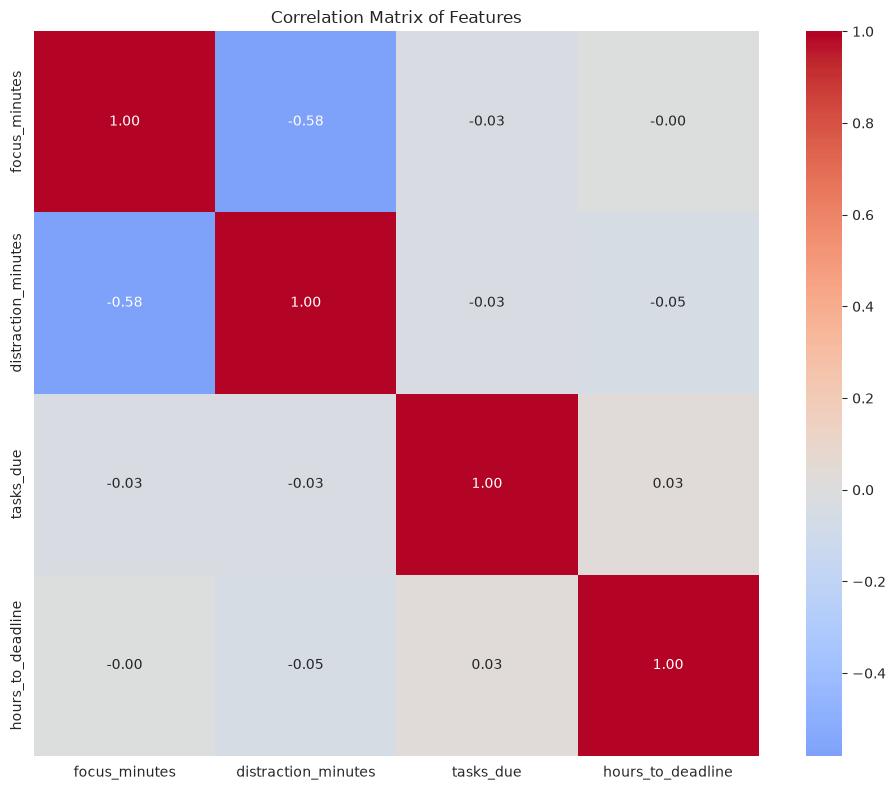

In [6]:
# Correlation matrix
numeric_cols = ["focus_minutes", "distraction_minutes", "tasks_due", "hours_to_deadline"]
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, square=True, fmt=".2f")
plt.title("Correlation Matrix of Features")
plt.tight_layout()
plt.show()


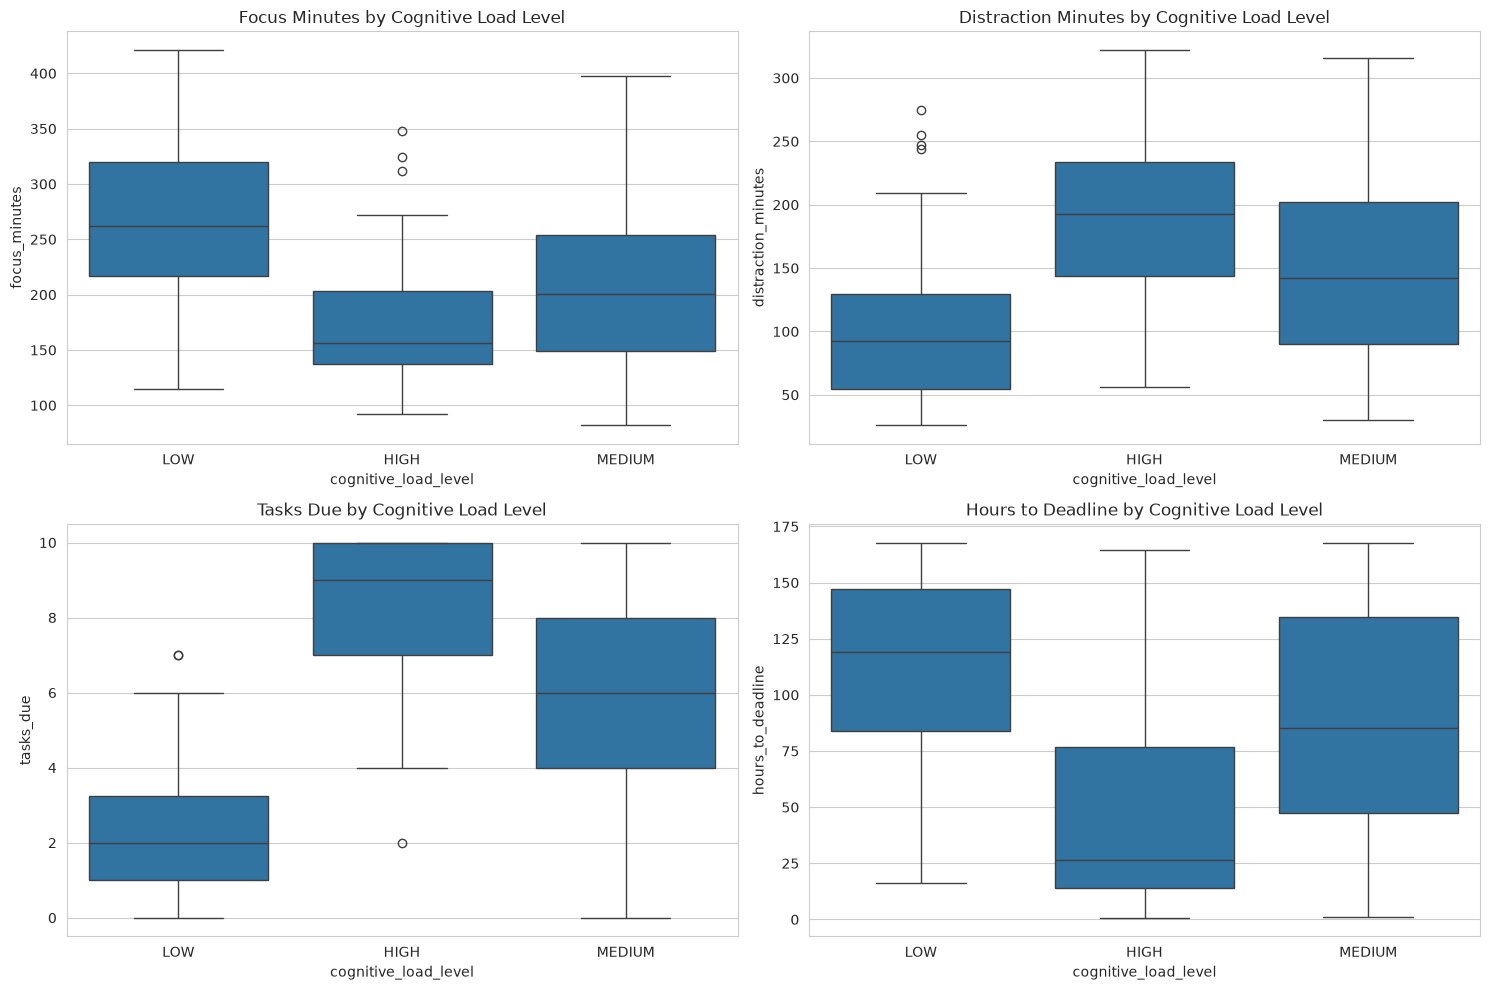

In [7]:
# Box plots by cognitive load level
if "cognitive_load_level" in df.columns:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    sns.boxplot(data=df, x="cognitive_load_level", y="focus_minutes", ax=axes[0, 0])
    axes[0, 0].set_title("Focus Minutes by Cognitive Load Level")
    
    sns.boxplot(data=df, x="cognitive_load_level", y="distraction_minutes", ax=axes[0, 1])
    axes[0, 1].set_title("Distraction Minutes by Cognitive Load Level")
    
    sns.boxplot(data=df, x="cognitive_load_level", y="tasks_due", ax=axes[1, 0])
    axes[1, 0].set_title("Tasks Due by Cognitive Load Level")
    
    sns.boxplot(data=df, x="cognitive_load_level", y="hours_to_deadline", ax=axes[1, 1])
    axes[1, 1].set_title("Hours to Deadline by Cognitive Load Level")
    
    plt.tight_layout()
    plt.show()


## Summary

### Key Findings:
1. **Data quality**: the deterministic sample has 500 rows, explicit `synthetic_proxy` provenance, and no missing values.
2. **Feature distributions**: focus/distraction cover the intentionally bounded synthetic ranges; class imbalance favors MEDIUM.
3. **Relationships**: correlations describe the generator, not observations from people.
4. **Label limitation**: labels are generated by the same demonstration rule evaluated later, so high scores measure rule fidelity only.

### Next Steps:
- Proceed to data processing notebook
- Reuse the shared train/serve feature contract
- Use chronological isolation and preserve label provenance
